# 2. The torus
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/2_torus.ipynb)

The torus $(\sqrt{x^2+y^2} - R)^2 + z^2 = a^2$ with $R = 1$, $a = 0.5$ has no exact solution, and it is the first shape for which the source surface is restricted (Sections 3.2 and 3.3 of the paper). The sources are electric dipoles on rings of an inner torus with minor radius $a_s$. Both the sources and the boundary points are invariant under a rotation about the axis, so the least-squares problem splits into one small problem per Fourier mode (`mfs/torus.py`).

In [1]:
# On Colab: get the code and the data (this cell does nothing when run locally)
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/MFS"):
        !git clone -q https://github.com/sap6/MFS /content/MFS
    sys.path.insert(0, "/content/MFS")            # numpy, scipy, numba and matplotlib come with Colab
    os.chdir("/content/MFS/notebooks")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import core, torus

k = 2 * np.pi
d, p = core.wave()             # along the axis of the torus, polarised along y
pts = 2.5 * core.sphere_rule(10, 20)[0]

## Convergence
Since no exact solution is available, we measure each run against a finer one, and we check the optical theorem: for a perfect conductor the extinction and scattering cross-sections must be equal.

In [3]:
ref = torus.scatter(k, d, p, 44, 160)           # 44 rings of 160 dipoles: 21120 unknowns
E_ref = ref.field(pts)
for ns, nphi in ((8, 28), (12, 40), (16, 52), (20, 64), (28, 96)):
    s = torus.scatter(k, d, p, ns, nphi)
    optical = torus.optical(s, d, p)[1]
    print(f"{3 * ns * nphi:6d} unknowns: difference from the finer run {core.rel(s.field(pts), E_ref):.1e}, "
          f"optical-theorem mismatch {optical:.1e}")

   672 unknowns: difference from the finer run 9.3e-02, optical-theorem mismatch 8.6e-03
  1440 unknowns: difference from the finer run 5.0e-03, optical-theorem mismatch 1.9e-03


  2496 unknowns: difference from the finer run 7.6e-04, optical-theorem mismatch 3.6e-04


  3840 unknowns: difference from the finer run 1.1e-04, optical-theorem mismatch 5.5e-05


  8064 unknowns: difference from the finer run 5.0e-07, optical-theorem mismatch 2.7e-07


## How thin may the source torus be?
The continued field appears to be singular on the focal ring of radius $\sqrt{R^2 - a^2}$, so the source torus must satisfy $a_s > R - \sqrt{R^2 - a^2}$ (a conjecture, supported numerically in the paper). For $a/R = 0.8$ the bound is $a_s / a = 0.5$, and the coefficients jump by orders of magnitude when the source torus crosses it (Figure 2).

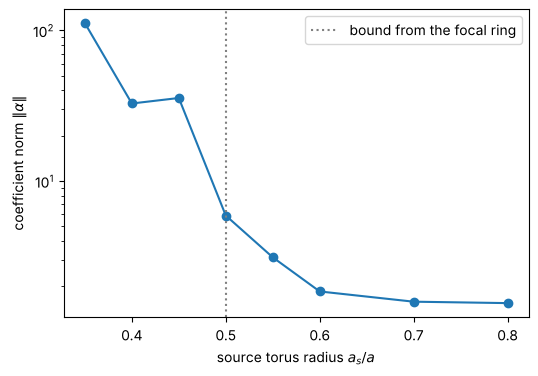

In [4]:
a = 0.8
fracs = (0.8, 0.7, 0.6, 0.55, 0.5, 0.45, 0.4, 0.35)
norms = [np.linalg.norm(torus.scatter(k, d, p, 24, 96, a=a, a_s=f * a).alpha) for f in fracs]
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(fracs, norms, "o-")
ax.axvline((1 - np.sqrt(1 - a ** 2)) / a, ls=":", color="grey", label="bound from the focal ring")
ax.set(xlabel="source torus radius $a_s / a$", ylabel=r"coefficient norm $\|\alpha\|$")
ax.legend()
plt.show()